# Сатылымды болжау


Сатылымды болжау — бизнесті жоспарлаудың маңызды бөлігі. Ол ұйымдарға болашақ сатылым көлемін алдын ала бағалауға және тауар қорын басқару, маркетингтік стратегиялар мен ресурстарды бөлу бойынша негізделген шешімдер қабылдауға көмектеседі.

Сатылымды болжау — деректердегі үрдістерге сүйене отырып, ағымдағы немесе болашақ сатылым көлемін бағалау үдерісі.

Төменде сатылымды болжау моделін кезең-кезеңімен жүзеге асыру берілген.

## 1. Қажетті кітапханаларды импорттау

Жұмысты бастамас бұрын қажетті кітапханалардың орнатылғанына көз жеткізіңіз. Бұл жоба барысында келесі кітапханалар қолданылады:

- [**pandas**](https://www.geeksforgeeks.org/pandas/pandas-tutorial/) — деректерді өңдеу және талдау үшін;
- [**matplotlib**](https://www.geeksforgeeks.org/python/python-introduction-matplotlib/) — графиктер құру үшін;
- [**seaborn**](https://www.geeksforgeeks.org/python/introduction-to-seaborn-python/) — деректерді визуализациялау үшін;
- [**XGBoost**](https://www.geeksforgeeks.org/machine-learning/xgboost/) — болжам моделін құру үшін;
- [**scikit-learn**](https://www.geeksforgeeks.org/machine-learning/learning-model-building-scikit-learn-python-machine-learning-library/) — деректерді бөлу және модельді бағалау үшін.

Оларды `pip` командасының көмегімен орнатуға болады:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

## 2. Деректер жиынтығын жүктеу

Бұл жұмыста `Row ID`, `Order ID`, `Customer ID` және басқа да белгілері бар сатылым деректерінің жиынтығы қолданылады.


In [3]:
file_path = '/content/train.csv'
data = pd.read_csv(file_path)

data.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


## 3. Деректерді алдын ала өңдеу және визуализациялау

Бұл бөлімде деректерді алдын ала өңдеп, сатылым көлемінің уақыт бойынша өзгеру динамикасын визуализациялаймыз.

- **`pd.to_datetime()`** — `Order Date` бағанындағы мәндерді күн мен уақыт форматына түрлендіреді. Бұл уақытқа байланысты операцияларды орындауға мүмкіндік береді.
- **`groupby()`** — деректерді `Order Date` бойынша топтастырып, әр күндегі сатылым көлемін қосады. Нәтижесінде күнделікті сатылымды көрсететін уақыттық қатар қалыптасады.

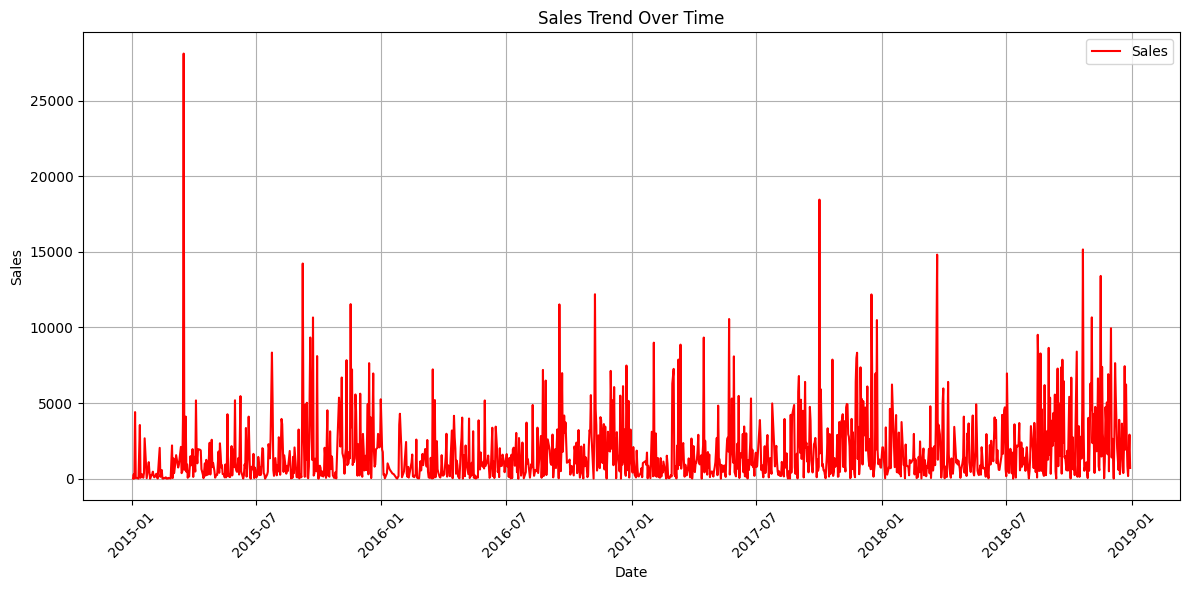

In [4]:
data['Order Date'] = pd.to_datetime(data['Order Date'], format='%d/%m/%Y')

sales_by_date = data.groupby('Order Date')['Sales'].sum().reset_index()

plt.figure(figsize=(12, 6))
plt.plot(sales_by_date['Order Date'], sales_by_date['Sales'], label='Sales', color='red')
plt.title('Sales Trend Over Time')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.grid(True)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 4. Белгілерді құрастыру — кешіктірілген белгілерді жасау

Бұл бөлімде сатылым деректеріндегі уақыттық заңдылықтарды анықтау үшін кешіктірілген белгілер (`lag features`) жасалады.

- **`create_lagged_features()`** — сатылым деректерін 1, 2, 3 және одан да көп уақыт қадамына жылжыту арқылы кешіктірілген белгілерді құратын функция. Бұл белгілер модельге алдыңғы күндердегі сатылым көрсеткіштері негізінде болашақ сатылымды болжауға көмектеседі.

Мысалы:

```text
Бүгінгі сатылым | 1 күн бұрын | 2 күн бұрын | 3 күн бұрын
      500       |     450     |     420     |     400
```

- **`dropna()`** — деректерді жылжыту (`shift`) кезінде пайда болған бос мәндері бар жолдарды жояды.

In [5]:
def create_lagged_features(data, lag=1):
    lagged_data = data.copy()
    for i in range(1, lag+1):
        lagged_data[f'lag_{i}'] = lagged_data['Sales'].shift(i)
    return lagged_data

lag = 5
sales_with_lags = create_lagged_features(data[['Order Date', 'Sales']], lag)

sales_with_lags = sales_with_lags.dropna()

## 5. Деректерді модельді оқытуға дайындау

Бұл қадамда деректерді модельді оқыту және тестілеу үшін дайындаймыз.

- **`drop(columns)`** — `X` белгілер жиынынан `Order Date` және `Sales` бағандарын алып тастайды. `Order Date` модельді оқытуға тікелей қолданылмайды, ал `Sales` — модель болжауы тиіс мақсатты айнымалы.

- **`train_test_split()`** — деректер жиынын оқыту және тестілеу бөліктеріне бөледі:

  - оқыту деректері — 80%;
  - тест деректері — 20%.

- **`shuffle=False`** — деректердің араластырылмауын қамтамасыз етеді. Деректер хронологиялық ретпен бөлініп, уақыттық қатардың құрылымы сақталады.

```text
Бұрынғы деректер                         Кейінгі деректер
┌───────────────────────────┐           ┌──────────────┐
│ Оқыту деректері — 80%     │           │ Тест — 20%   │
└───────────────────────────┘           └──────────────┘
────────────── уақыт бағыты ───────────────────────────→
```

In [6]:
X = sales_with_lags.drop(columns=['Order Date', 'Sales'])
y = sales_with_lags['Sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

## 6. XGBoost моделін оқыту

Бұл бөлімде XGBoost моделін оқытамыз. XGBoost — жоғары дәлдіктегі болжам модельдерін құру үшін [**градиенттік бустингті**](https://www.geeksforgeeks.org/machine-learning/ml-gradient-boosting/) қолданатын машиналық оқыту алгоритмі. Ол сатылымды болжау сияқты регрессиялық есептерге өте қолайлы.

- **`XGBRegressor`** — регрессиялық есептерге арналған XGBoost моделін құрады.

- **`objective='reg:squarederror'`** — модельдің үздіксіз сандық мәндерді болжайтын регрессиялық есепті шешетінін көрсетеді. Бұл жағдайда модель сатылым көлемін болжайды.

- **`learning_rate` (`lr`)** — әр итерацияда модель салмақтарының қаншалықты өзгеретінін анықтайды. Кіші мән модельдің баяу, бірақ тұрақты үйренуіне мүмкіндік береді.

- **`n_estimators`** — құрылатын шешім ағаштарының немесе бустинг қадамдарының саны. Ағаштар саны артқан сайын модель дәлірек болуы мүмкін, бірақ шамадан тыс үйрену қаупі де жоғарылайды.

- **`max_depth`** — әр шешім ағашының максималды тереңдігін анықтайды. Терең ағаштар күрделі заңдылықтарды үйрене алады, алайда шамадан тыс үйренуге бейім болуы мүмкін.

- **`fit()`** — модельді оқыту деректерімен (`X_train`, `y_train`) оқытады.

In [7]:
model_xgb = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, learning_rate=0.1, max_depth=5)
model_xgb.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

### 7. Болжам жасау және модельді бағалау
Бұл бөлімде оқытылған модель арқылы болжам жасап, оның жұмыс сапасын RMSE метрикасы арқылы бағалаймыз.
- predict() — оқытылған XGBoost моделін пайдаланып, тест деректері (X_test) үшін сатылым көлемін болжайды.
- mean_squared_error() — нақты және болжанған мәндер арасындағы орташа квадраттық қатені (MSE) есептейді.
- np.sqrt() — MSE мәнінің квадрат түбірін есептеп, RMSE көрсеткішін анықтайды. RMSE — регрессиялық модельдердің сапасын бағалауға арналған негізгі метрикалардың бірі.

In [9]:
import numpy as np

predictions_xgb = model_xgb.predict(X_test)
rmse_xgb = np.sqrt(mean_squared_error(y_test, predictions_xgb))

print(f"RMSE: {rmse_xgb:.2f}")

RMSE: 735.58


**RMSE = 734,63** мәні нақты және болжанған сатылым көрсеткіштері арасындағы орташа ауытқудың шамамен **734,63 сатылым бірлігіне** тең екенін білдіреді.

RMSE мәні неғұрлым төмен болса, модельдің болжамдары нақты сатылым көрсеткіштеріне соғұрлым жақын болады. Сатылым мәндерінің ауқымы үлкен болғандықтан, бұл RMSE нәтижесін қолайлы деп бағалауға болады. Дегенмен, нақты қорытынды жасау үшін RMSE мәнін сатылымның орташа көлемімен немесе қарапайым базалық модельдің нәтижесімен салыстыру қажет.

## 8. Нәтижелерді визуализациялау

Модельдің жұмыс сапасын көрнекі түрде салыстыру үшін нақты және болжанған сатылым көрсеткіштерін бір графикте бейнелейміз.

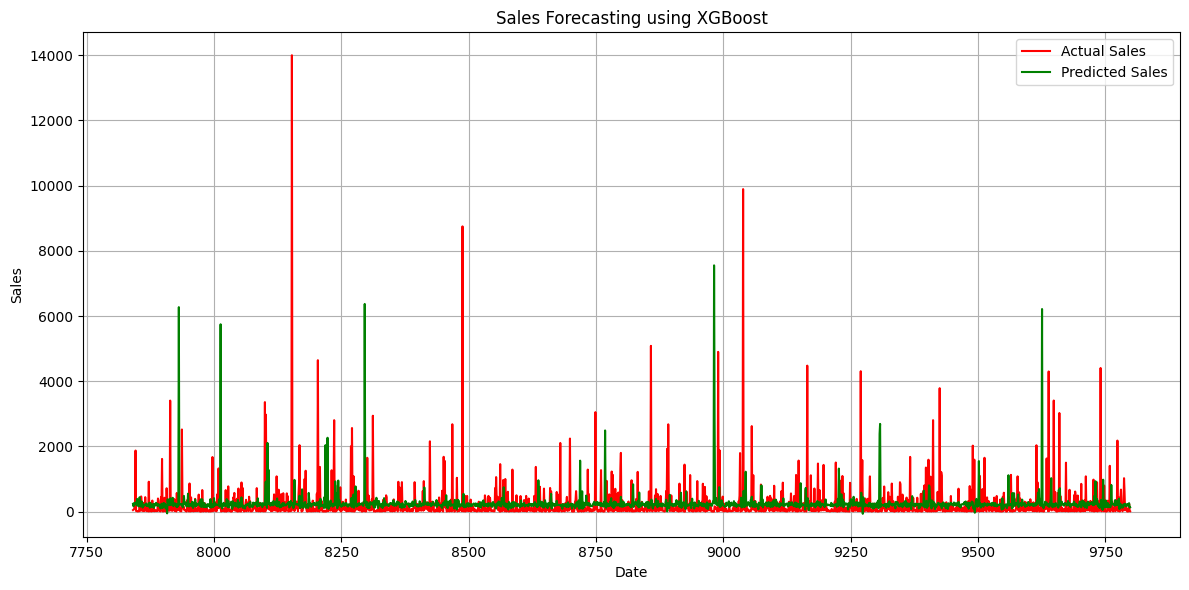

In [10]:
plt.figure(figsize=(12, 6))
plt.plot(y_test.index, y_test, label='Actual Sales', color='red')
plt.plot(y_test.index, predictions_xgb, label='Predicted Sales', color='green')
plt.title('Sales Forecasting using XGBoost')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Графиктен болжанған және нақты сатылым мәндерінің бір-біріне жақын екенін көруге болады. Бұл модельдің сатылым динамикасын жеткілікті деңгейде үйренгенін көрсетеді.

XGBoost сияқты машиналық оқыту модельдерін пайдалану тарихи деректердегі уақыттық заңдылықтарды анықтап, сатылым болжамдарының дәлдігін арттыруға мүмкіндік береді. Мұндай модельдер бизнеске:

- тауар қорын тиімді басқаруға;
- баға белгілеу стратегиясын оңтайландыруға;
- болашақ сұранысты жоспарлауға;
- ресурстарды дұрыс бөлуге көмектеседі.

Дегенмен, модельдің тиімділігін тек график бойынша емес, **RMSE, MAE және R²** сияқты бағалау метрикалары арқылы да тексеру қажет.